<a href="https://colab.research.google.com/github/Franklin465105/machinelearningproject-ml/blob/main/CampusDatasetprojectexample.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Campus Dataset Example

## Data Preparation
This section loads the campus dataset and prepares it for analysis.

In [2]:
import pandas as pd

## Load the Dataset

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
df = pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/campus.csv',
    skiprows = 4
    )

## Inspect Dataset structure

In [4]:
print("Column Names")
print(df.dtypes)

print("\nSample Rows\n")
print(df.head())

Column Names
recorder_id                               object
date                                      object
location                                  object
weather                                  float64
temperature_c                            float64
sound_level                               object
foot_traffic                              object
primary_sound_type_urban                  object
other_sound_type_urban                    object
primary_sound_type_nature                float64
other_sound_type_nature                  float64
insects_count                            float64
birds_count                              float64
trees_presence                            object
native_or_wild_plant_presence             object
ornnamental_or_planted_plant_presence     object
moss_or_lichen_presence                   object
wellbeing_rating                          object
ease_rating                               object
stress_rating                             object
nature_

## Analyzing Missing Data
We're going to see which columns have complete information and which ones have significant gaps and display them in a bar chart.


In [17]:
# Calculate total and percentage of missing values per column
missing_data = df.isnull().sum().to_frame(name='Missing Values')
missing_data['Percentage (%)'] = (missing_data['Missing Values'] / len(df) * 100).round(2)
missing_data = missing_data.sort_values(by='Missing Values', ascending=False)

display(missing_data)

,Missing Values,Percentage (%)
weather,995,100.00
primary_sound_type_nature,995,100.00
other_sound_type_nature,995,100.00
most_notable_nature_element,995,100.00
other_notes,995,100.00
temperature_c,970,97.49
date,970,97.49
birds_count,970,97.49
insects_count,970,97.49
recorder_id,0,0.00


### Visualizing Missing Values
We will now display the missing data summary and use a bar chart to clearly identify which features have high percentages of missing entries.

Missing Data Summary Table:


,Missing Values,Percentage (%)
weather,995,100.00
primary_sound_type_nature,995,100.00
other_sound_type_nature,995,100.00
most_notable_nature_element,995,100.00
other_notes,995,100.00
temperature_c,970,97.49
date,970,97.49
birds_count,970,97.49
insects_count,970,97.49
recorder_id,0,0.00


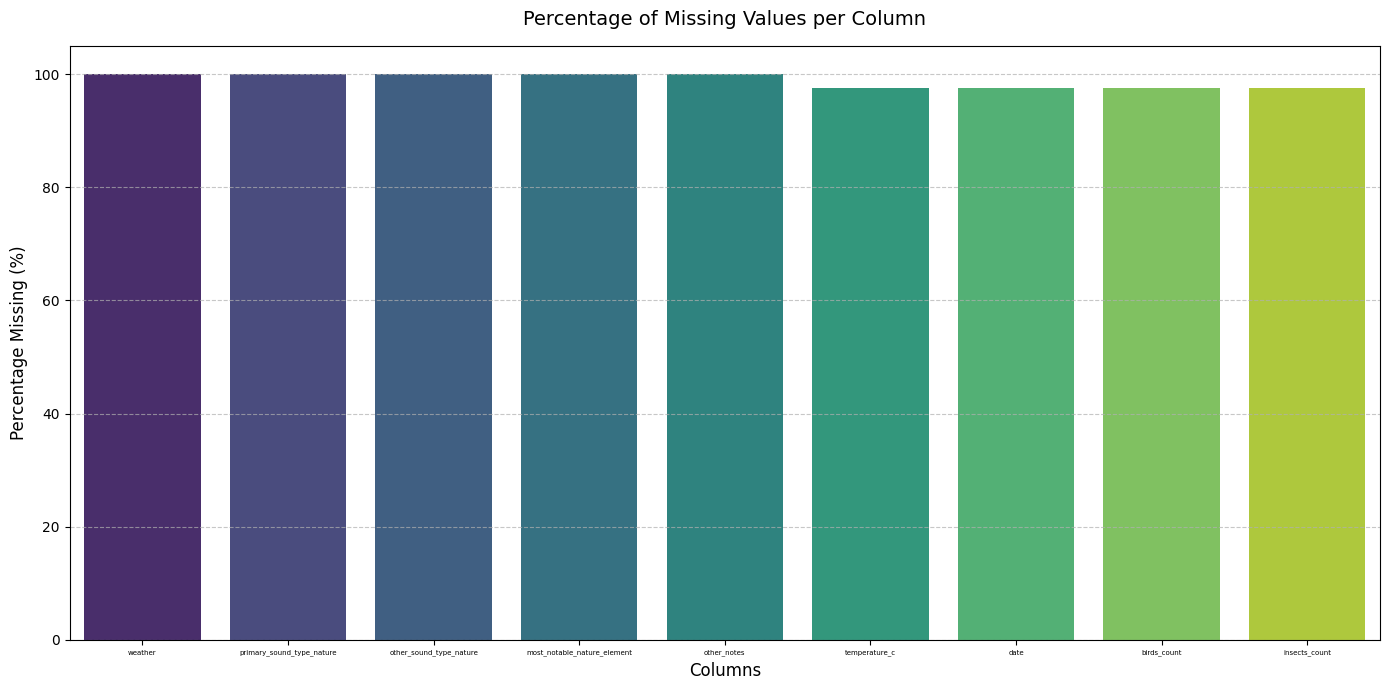

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Display the structured missing data summary table
print("Missing Data Summary Table:")
display(missing_data)

# Filter columns that have at least one missing value for the plot
missing_filtered = missing_data[missing_data['Missing Values'] > 0]

if not missing_filtered.empty:
    plt.figure(figsize=(14, 7))
    sns.barplot(
        x=missing_filtered.index,
        y=missing_filtered['Percentage (%)'],
        palette='viridis',
        hue=missing_filtered.index,
        legend=False
    )
    plt.title('Percentage of Missing Values per Column', fontsize=14, pad=15)
    plt.xlabel('Columns', fontsize=12)
    plt.ylabel('Percentage Missing (%)', fontsize=12)
    # Set rotation to 0 for horizontal labels, and use wrap or smaller font if needed to prevent overlaps
    plt.xticks(rotation=0, fontsize=5)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset!")